In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
import ipywidgets as widgets
from ipywidgets import interact, interactive_output, VBox, HBox
import random
import pandas as pd
import os
import glob
import re
import sys
import pickle 
import scipy 
from copy import deepcopy
from hmmlearn import hmm
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
import itertools

# sns.set_style('whitegrid')

# plot formatting (Hansen Lab style guide)
plt.rc("pdf", fonttype=42)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial"]
plt.rcParams["font.size"] = 6
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.linewidth"] = 0.25
plt.rcParams["axes.titlesize"] = 6
plt.rcParams["axes.labelsize"] = 6
plt.rcParams["xtick.major.width"] = 0.25
plt.rcParams["xtick.minor.width"] = 0.25
plt.rcParams["xtick.labelsize"] = 6
plt.rcParams["ytick.major.width"] = 0.25
plt.rcParams["ytick.minor.width"] = 0.25
plt.rcParams["ytick.labelsize"] = 6
plt.rcParams["legend.fontsize"] = 6
plt.rcParams["legend.frameon"] = False
plt.rcParams["legend.facecolor"] = "none"
plt.rcParams["lines.linewidth"] = 1.00
plt.rcParams["text.usetex"] = False
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["ps.useafm"] = True

# colors (Hansen Lab style guide)
colors = {"blue": (0.000,0.467,0.733),
          "cyan": (0.200,0.733,0.933),
          "teal": (0.000,0.600,0.533),
          "orange": (0.933,0.467,0.200),
          "red": (0.800,0.200,0.067),
          "magenta": (0.933,0.200,0.467),
          "grey": (0.733,0.733,0.733)}
# --- Try Imports for specific libraries ---
try:
    import bayesmsd
    import bayesmsd.parameters
    import bayesmsd.deco
    import noctiluca as nl
    from scipy.special import erfc
    from scipy import optimize
except ImportError:
    raise ImportError("This analysis requires 'bayesmsd' and 'noctiluca' libraries installed.")



---

In [ ]:
all_params = {}
conditions = ['unt', 'dCtcf', 'dRad21', 'txn', 'trp']
for condition in conditions:
    with open(f'./bild/bild_outputs/fit_params/{condition}_fit_params.pkl', 'rb') as f:
        all_params[condition] = pickle.load(f)

## 1. Data loading

In [3]:
def data_from_npzs(filtered_folder):
    track_dfs = []
    # loop over npz files for each available condition
    for f in glob.glob(filtered_folder+'/*.npz'):
        print(f)
        condition = os.path.splitext(os.path.basename(f))[0].split(sep='_')[1]
        with np.load(f) as data:
            for i in range(len(data['identifiers'])):
                # unpack data into dataframe
                dataframe = pd.DataFrame()
                # convert from nm to um
                dataframe['rel_x'] = data['dataset'][i,:,0]/1000
                dataframe['rel_y'] = data['dataset'][i,:,1]/1000
                dataframe['rel_z'] = data['dataset'][i,:,2]/1000
                # calculate Euclidean distance
                dataframe['locus_distance_um'] = np.sqrt(dataframe['rel_x']**2+
                                                        dataframe['rel_y']**2+
                                                        dataframe['rel_z']**2)
                # more data unpacking
                dataframe['frame'] = range(data['dataset'].shape[1])
                dataframe['QC_Status'] = 'After QC'
                dataframe['TrackID'] = data['identifiers'][i]
                dataframe['Condition'] = condition
                dataframe['intensity (au)'] = data['intensity'][i,:]
                dataframe['background (au)'] = data['background'][i,:]
                track_dfs.append(dataframe)
    # concatenate all tracks into one dataframe
    reconstituted_df = pd.concat(track_dfs,ignore_index=True)
    return reconstituted_df

def extract_intensity_series(dataset, condition, norm_condition='unt', smooth_window=None):
    sequence = []
    lengths = []
    # get data for just the condition of interest and separate by individual track
    cond_data = dataset[dataset['Condition']==condition].groupby('TrackID',sort=False)
    SMOOTH=False
    if type(smooth_window)==int:
        if smooth_window%2==1:
            print(f"Smoothing intensities with window size {smooth_window}...")
            SMOOTH=True
        else:
            print("Smoothing window size must be odd! No smoothing will be performed.")
    else:
        print("No smoothing performed")
    for i, track in cond_data:
        intensities = track['intensity (au)']
        # Normalize intensity values by sample standard deviation to account for track-to-track variability
        # default to using mean of untreated condition as mean
        norm_factor = np.sqrt(np.nansum((intensities-np.nanmean(
            df_comparison['intensity (au)'].loc[df_comparison['Condition']==norm_condition]))**2)/
            (len(~np.isnan(intensities)-1)))
        intensities = (intensities-np.nanmean(df_comparison['intensity (au)'].loc[df_comparison['Condition']==norm_condition]))/norm_factor
        if SMOOTH:
                intensities = intensities.rolling(smooth_window,center=True,closed='both').mean().to_numpy()
        else:
            intensities = intensities.to_numpy()
        # intensities = intensities.rolling(5,min_periods=3,center=True,closed='both').mean().to_numpy()
        if len(np.argwhere(~np.isnan(intensities)))>0:
            first_good = np.min(np.argwhere(~np.isnan(intensities)))
            last_good = np.max(np.argwhere(~np.isnan(intensities)))
            intensities = deepcopy(intensities[first_good:last_good+1])
            intensities = pd.Series(intensities).interpolate().to_numpy()
            sequence.append(intensities)
            lengths.append(len(intensities))
    emission = np.concatenate(sequence).reshape(-1,1)
    return emission, lengths

def map_HMM_states(df, condition, states, lengths, inplace=False):
    if not 'HMM State' in df.columns:
        df['HMM State'] = np.nan
    state_map = np.full(len(df[df['Condition']==condition]),np.nan)
    df_start = 0
    state_start = 0
    i = 0
    tracks = df[df['Condition']==condition].groupby('TrackID',sort=False)
    for trackID, track in tracks:
        intensities = track['intensity (au)'].to_numpy()
        if len(np.argwhere(~np.isnan(intensities)))>0:
            first_good = np.min(np.argwhere(~np.isnan(intensities)))
            state_map[df_start+first_good:df_start+first_good+lengths[i]] = states[state_start:state_start+lengths[i]]
            state_start+=lengths[i]
            df_start+=len(intensities)
            i+=1
        else:
            df_start+=len(intensities)
    # print(state_map)
    df.loc[df['Condition']==condition,'HMM State'] = state_map
    if not inplace:
        return df

def infer_bursts(df,train_cond,n_components=2,norm_condition='unt',train_smooth=None,
                 predict_smooth=None,model_file=None,train_iterations=10):
    train_emission, train_lengths = extract_intensity_series(df, train_cond,norm_condition=norm_condition,smooth_window=train_smooth)
    if model_file==None:
        aics = []
        best_aic = np.nan
        model = None
        for i in range(train_iterations):
            test_model = hmm.GaussianHMM(n_components=n_components,random_state=i).fit(train_emission,train_lengths)
            test_aic = test_model.aic(train_emission,train_lengths)
            if np.isnan(best_aic) or test_aic<best_aic:
                model = test_model
                best_aic=test_aic
            aics.append(test_aic)
        # model = hmm.GaussianHMM(n_components=n_components).fit(train_emission,train_lengths)
    else:
        with open(model_file,'rb') as f:
            model = pickle.load(f)
        aics = [model.aic(train_emission,train_lengths)]
    out_df = deepcopy(df)
    for cond in df['Condition'].unique():
        emission, lengths = extract_intensity_series(df,cond,norm_condition=norm_condition,smooth_window=predict_smooth)
        logP, states = model.decode(emission,lengths)
        out_df = map_HMM_states(out_df,cond,states,lengths)
    on_state = np.argmax(model.means_,axis=0)[0]
    # print(on_state)
    out_df['Burst'] = 'off'
    out_df.loc[np.isin(out_df['HMM State'],on_state),'Burst'] = 'on'
    out_df.loc[np.isnan(out_df['intensity (au)']),'Burst'] = np.nan
    return out_df,model,train_emission,aics



In [4]:
filtered_df = data_from_npzs('/mnt/md1/Jamie/filtered_tracks')
df_comparison = filtered_df
df_comparison, model, train_emission, aics = infer_bursts(df_comparison,'txn',n_components=2,
                                                    norm_condition='unt',model_file='/mnt/md0/Jamie/analysis/2state_burst_HMM_norm_smoothed.pkl',
                                                    train_smooth=5,predict_smooth=5,train_iterations=10)
df_comparison

/mnt/md1/Jamie/filtered_tracks/30s_dCtcf.npz
/mnt/md1/Jamie/filtered_tracks/30s_dRad21.npz
/mnt/md1/Jamie/filtered_tracks/30s_unt.npz
/mnt/md1/Jamie/filtered_tracks/30s_txn.npz
/mnt/md1/Jamie/filtered_tracks/30s_trp.npz
Smoothing intensities with window size 5...
Smoothing intensities with window size 5...
Smoothing intensities with window size 5...
Smoothing intensities with window size 5...
Smoothing intensities with window size 5...
Smoothing intensities with window size 5...


,rel_x,rel_y,rel_z,locus_distance_um,frame,QC_Status,TrackID,Condition,intensity (au),background (au),HMM State,Burst
0,0.002288,-0.015928,0.167033,0.167806,0,After QC,159_0_3_20260502_20260502_3_159_000,dCtcf,-4.509,293.122,1.0,off
1,0.000992,0.221897,-0.272869,0.351705,1,After QC,159_0_3_20260502_20260502_3_159_000,dCtcf,-5.878,286.648,1.0,off
2,0.034255,-0.090267,0.409581,0.420807,2,After QC,159_0_3_20260502_20260502_3_159_000,dCtcf,-4.592,286.132,1.0,off
3,0.135063,0.061959,-0.550624,0.570322,3,After QC,159_0_3_20260502_20260502_3_159_000,dCtcf,3.721,295.156,1.0,off
4,NaN,NaN,NaN,NaN,4,After QC,159_0_3_20260502_20260502_3_159_000,dCtcf,NaN,NaN,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
491481,NaN,NaN,NaN,NaN,354,After QC,2_0_2_20260415_20260415_2_002_000,trp,-2.427,184.498,1.0,off
491482,NaN,NaN,NaN,NaN,355,After QC,2_0_2_20260415_20260415_2_002_000,trp,-0.990,174.502,NaN,off
491483,NaN,NaN,NaN,NaN,356,After QC,2_0_2_20260415_20260415_2_002_000,trp,0.547,202.951,NaN,off
491484,NaN,NaN,NaN,NaN,357,After QC,2_0_2_20260415_20260415_2_002_000,trp,2.693,225.385,NaN,off


In [59]:
with open('2state_burst_HMM_norm_smoothed.pkl','wb') as f:
    pickle.dump(model,f)

In [5]:
# Load inference data
conditions = ['unt', 'dCtcf', 'dRad21', 'txn', 'trp']
colors_dict = {
    'unt': '#BBBBBB',
    'txn': '#0077BB',
    'trp': '#ee7733',
    'dRad21': '#33bbee',
    'dCtcf': '#cc3311'
    }
names_dict = {
    'unt': 'untreated',
    'txn': '+ABA',
    'trp': '+ABA +triptolide',
    'dRad21': '\u0394RAD21 (4h)',
    'dCtcf': '\u0394CTCF (4h)'
    }

final_inferences_all = {}
track_names_all = {}

for condition in conditions:
    save_folder = f'/mnt/md1/Jamie/bild_outputs/bild_profiles/{condition}_initial_dE_2.0'

    filenames = [os.path.basename(fn) for fn in glob.glob(os.path.join(save_folder,'*'))]

    profile_info = []
    for fn in filenames:
        track_name, suffix = fn.split('_bild_result_frame_')
        frames_str = suffix[:-4]
        start_frame, end_frame = frames_str.split('_to_')
        start_frame = int(start_frame)
        end_frame = int(end_frame)
        profile_info.append({'track_name': track_name,
                            'start_frame': start_frame,
                            'end_frame': end_frame,
                            'filename': fn})
        
    profile_info = pd.DataFrame(profile_info)
    profile_info = profile_info.sort_values(['track_name', 'start_frame'])
    profile_info.index = np.arange(len(profile_info))

    track_names = np.unique(profile_info['track_name'])

    max_unchopped_traj_len = np.max(profile_info['end_frame'])

    # make matrix to store inferences; store multiple inferences along 3rd dimension
    inferences = np.zeros((len(track_names), max_unchopped_traj_len, 2), dtype='int8') * np.nan
    dist_from_end = np.zeros(inferences.shape, dtype='int') * np.nan

    dE = 2
    for track_name_idx in range(len(track_names)):
        track_name = track_names[track_name_idx]
        profiles_this_track = profile_info.loc[profile_info['track_name']==track_name]
        for i in range(len(profiles_this_track)):
            track_name, start_frame, end_frame, fn = profiles_this_track.iloc[i]
            bild_result = pickle.load(open(os.path.join(save_folder, fn), 'rb'))
            best_profile = bild_result.best_profile(dE=dE)
            best_profile = np.array(list(best_profile)).astype('int8')
            best_profile = pd.Series(best_profile, index=np.arange(start_frame, end_frame))
            for frame_num in range(start_frame, end_frame):
                k = 0
                while not np.isnan(inferences[track_name_idx, frame_num, k]):
                    k += 1
                    if k > inferences.shape[2]:
                        raise RuntimeError('3rd dimension of inferences not large enough!')
                inferences[track_name_idx, frame_num, k] = best_profile[frame_num]
                dist_from_end[track_name_idx, frame_num, k] = min(frame_num-start_frame, end_frame-frame_num)

    final_inferences = np.zeros((inferences.shape[0], inferences.shape[1])) * np.nan
    for track_name_idx in range(len(track_names)):
        for frame_num in range(max_unchopped_traj_len):
            inf1 = inferences[track_name_idx, frame_num, 0]
            inf2 = inferences[track_name_idx, frame_num, 1]
            if np.isnan(inf1) and np.isnan(inf2):
                inf = np.nan
            elif np.isnan(inf2):
                inf = inf1
            elif inf1 != inf2:
                if dist_from_end[track_name_idx, frame_num, 0] > dist_from_end[track_name_idx, frame_num, 1]:
                    inf = inf1
                else:
                    inf = inf2
            else:
                inf = inf1  # doesn't matter, they will be the same
            final_inferences[track_name_idx, frame_num] = inf

    track_names_all[condition] = track_names
    final_inferences_all[condition] = final_inferences.copy()

/home/jdrayton/miniconda3/envs/msd/lib/python3.9/site-packages/bild/cython_imports.py:6: UserWarning: Did not find compiled code for MSRouse_logL, falling back to python
  warn("Did not find compiled code for MSRouse_logL, falling back to python")


In [6]:
# Map BILD states to tracks in df_comparison
df_comparison['BILD state']=np.nan
new_groups = []
BILD_to_pipeline = {}
for cond in conditions:
    track_mappings = pd.read_csv(f'/mnt/md1/Jamie/bild_outputs/trajectory_mappings/{cond}_100frames.tsv',index_col=0,
                                 header=None,names=['pipeline TrackID'])
    track_mappings['BILD trackname'] = [f'original_track_{i}' for i in range(len(track_mappings))]
    mapdict = dict(zip(track_mappings['pipeline TrackID'],track_mappings['BILD trackname']))
    BILDdict = dict(zip(track_names_all[cond],final_inferences_all[cond]))
    BILD_to_pipeline[cond] = dict(zip(track_mappings['BILD trackname'],track_mappings['pipeline TrackID']))
    data = df_comparison[df_comparison['Condition']==cond]
    for trackid, track in data.groupby('TrackID',sort=False):
        if trackid in mapdict.keys():
            inferences = BILDdict[mapdict[trackid]]
            inferences = np.append(inferences,[np.nan]*(len(track)-len(inferences)))
            track['BILD state']=inferences
            new_groups.append(track)
            # print(track['BILD state'])
        else:
            new_groups.append(track)
new_df = pd.concat(new_groups)
df_comparison = new_df

In [12]:
# to print which profiles satisfy certain length criteria
for i in range(len(final_inferences_all['txn'])):
    profile = final_inferences_all['txn'][i,:]
    profile = profile[:np.where(~np.isnan(profile))[0][-1] + 1]  # remove trailing NaNs
    if np.abs(len(profile)-310)<=50:
        print(i, len(profile), BILD_to_pipeline['txn'][track_names_all['txn'][i]])
    # if sum(profile)>=0.06*len(profile):
    #     print(i, sum(profile)/len(profile), len(profile))

1 350 49_0_1_20260314_20260314_1_049_000
3 350 114_0_2_20260502_20260502_2_114_000
32 350 8_0_3_20260330_20260330_3_008_000
35 350 55_0_1_20260314_20260314_1_055_000
36 300 26_0_4_20260314_20260314_4_026_000
40 350 99_0_4_20260314_20260314_4_099_000
45 300 67_0_4_20260330_20260330_4_067_000
47 350 56_0_4_20260330_20260330_4_056_000
52 350 2_0_4_20260330_20260330_4_002_000
90 300 27_0_1_20260314_20260314_1_027_000
133 350 52_0_6_20260330_20260330_6_052_000
140 350 96_0_2_20260330_20260330_2_096_000
164 350 22_0_1_20260317_20260317_1_022_000
171 300 80_1_1_20260317_20260317_1_080_001
196 350 97_0_2_20260411_20260411_2_097_000
261 300 185_0_3_20260502_20260502_3_185_000
267 350 60_0_1_20260314_20260314_1_060_000
289 300 63_0_1_20260314_20260314_1_063_000
292 300 31_0_2_20260502_20260502_2_031_000


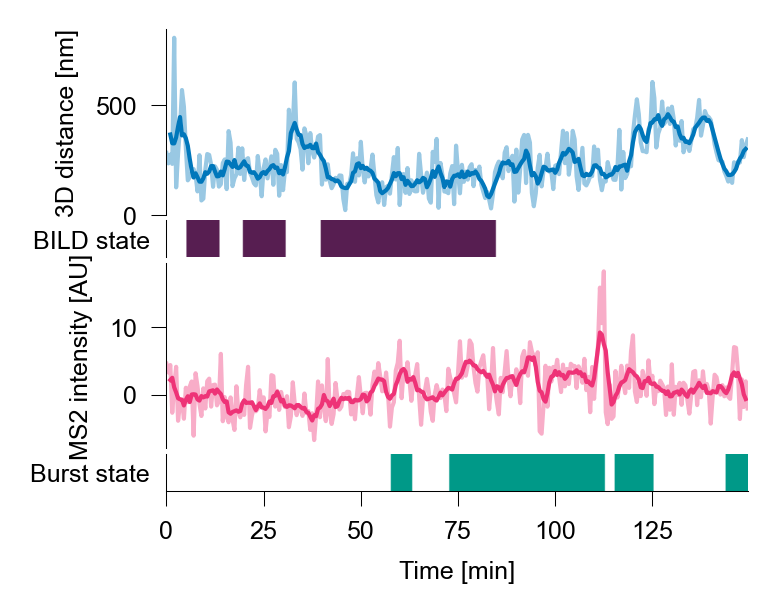

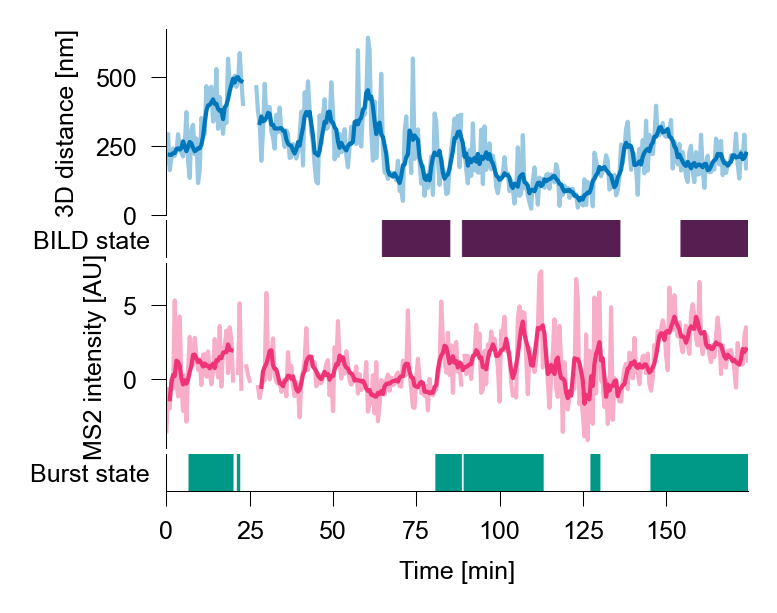

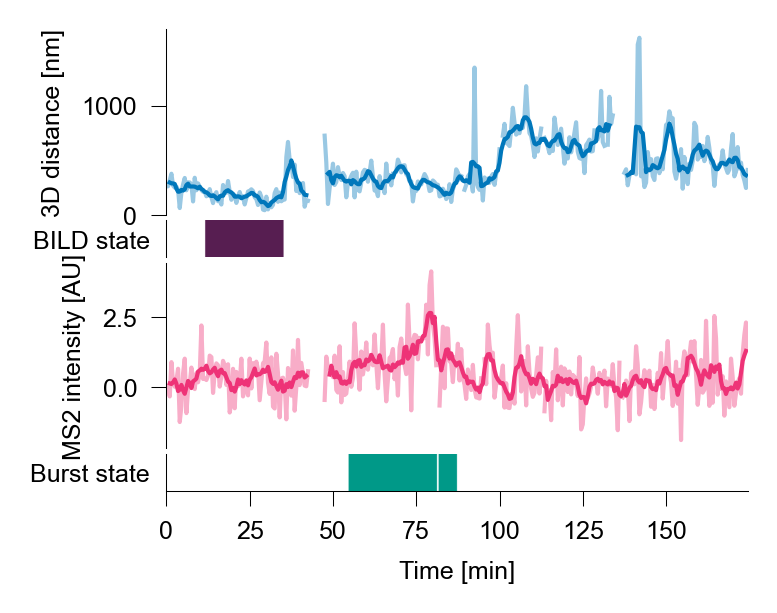

In [77]:
def plot_track_with_profiles(data,trackID,condition,ymin=0,ymax=None,savepath=None):
    # data extraction
    dists = data['locus_distance_um'].loc[(data['Condition']==condition)&(data['TrackID']==trackID)].to_numpy()
    intensities = data['intensity (au)'].loc[(data['Condition']==condition)&(data['TrackID']==trackID)].to_numpy()
    BILD_profile = data['BILD state'].loc[(data['Condition']==condition)&(data['TrackID']==trackID)].to_numpy()
    burst_profile = data['Burst'].loc[(data['Condition']==condition)&(data['TrackID']==trackID)]
    burst_profile = np.array([1 if i=='on' else 0 for i in burst_profile])
    BILD_profile = BILD_profile[:np.where(~np.isnan(BILD_profile))[0][-1] + 1] # remove trailing NaNs
    dists = dists[:len(BILD_profile)]
    dists_smoothed = pd.Series(dists).rolling(5,center=True,closed='both').mean().to_numpy()
    intensities = intensities[:len(BILD_profile)]
    intensities_smoothed = pd.Series(intensities).rolling(5,center=True,closed='both').mean().to_numpy()
    burst_profile = burst_profile[:len(BILD_profile)]

    t_minutes = np.arange(len(dists)) * 30/60
    extent_L = t_minutes[0]-0.25
    extent_R = t_minutes[-1]+0.25
    # print(extent_L,extent_R)

    fig, axs = plt.subplots(4,1,gridspec_kw={'height_ratios': [5, 1, 5, 1], 'hspace': 0.05},figsize=(2.5,2), dpi=300, frameon=False)
    cmap = LinearSegmentedColormap.from_list("white_purple", ["white", "#571e51"])
    cmap2 = LinearSegmentedColormap.from_list("white_teal", ["white", "#009988"])
    axs[0].plot(t_minutes, dists*1000, color=colors_dict[condition], alpha=0.4, linewidth=1)
    axs[0].plot(t_minutes,dists_smoothed*1000, color=colors_dict[condition], linewidth=1)
    axs[0].set_xlim(t_minutes[0], t_minutes[-1])
    axs[0].set_ylabel('3D distance [nm]');
    axs[0].set_xticks([])
    axs[0].set_ylim(ymin, ymax)
    axs[0].spines[['bottom', 'top', 'right']].set_visible(False)
    axs[1].imshow(BILD_profile.reshape((1, len(BILD_profile))), aspect='auto', extent=[extent_L, extent_R, 0, 1], cmap=cmap)
    # axs[1].imshow(BILD_profile.reshape((1, len(BILD_profile))), aspect=len(BILD_profile)/25, origin='lower', cmap=cmap)
    axs[1].set_xlim(t_minutes[0], t_minutes[-1])
    axs[1].set_yticks([]);
    axs[1].set_xticks([])
    axs[1].spines[['bottom', 'top', 'right']].set_visible(False)
    axs[1].set_ylabel('BILD state',rotation='horizontal',ha='right',va='center_baseline')
    axs[2].plot(t_minutes, intensities, color='#ee3377',alpha=0.4, linewidth=1)
    axs[2].plot(t_minutes, intensities_smoothed, color='#ee3377', linewidth=1)
#     axs[2].plot(t_minutes,[np.nanmean(
#             df_comparison['intensity (au)'].loc[df_comparison['Condition']=='unt'])]*len(t_minutes),'--k',alpha=0.7)
    axs[2].set_xlim(t_minutes[0], t_minutes[-1])
    axs[2].set_ylabel('MS2 intensity [AU]');
    axs[2].set_xticks([])
    axs[2].spines[['bottom', 'top', 'right']].set_visible(False)
    axs[3].imshow(burst_profile.reshape((1, len(burst_profile))), aspect='auto', extent=[extent_L, extent_R, 0, 1], cmap=cmap2)
    axs[3].set_xlim(t_minutes[0], t_minutes[-1])
    axs[3].set_yticks([]);
    axs[3].set_ylabel('Burst state',rotation='horizontal',ha='right',va='center_baseline')
    axs[3].set_xlabel('Time [min]');

    if savepath!=None:
        plt.savefig(savepath,transparent=True,bbox_inches='tight')

plot_track_with_profiles(df_comparison,'67_0_4_20260330_20260330_4_067_000','txn',
                         savepath='Figures/example_track_1.svg')
plot_track_with_profiles(df_comparison,'55_0_1_20260314_20260314_1_055_000','txn',
                         savepath='Figures/example_track_2.svg')
plot_track_with_profiles(df_comparison,'60_0_1_20260314_20260314_1_060_000','txn',
                         savepath='Figures/example_track_3.svg')

In [7]:
txn_data = df_comparison[(df_comparison['Condition']=='txn') & (~np.isnan(df_comparison['BILD state'])) & (~np.isnan(df_comparison['HMM State']))]
n_both = len(txn_data[(txn_data['Burst']=='on')&(txn_data['BILD state']==1)])
n_on = len(txn_data[(txn_data['Burst']=='on')&(txn_data['BILD state']==0)])
n_loop = len(txn_data[(txn_data['Burst']=='off')&(txn_data['BILD state']==1)])
n_neither = len(txn_data[(txn_data['Burst']=='off')&(txn_data['BILD state']==0)])
print((n_both,n_on,n_loop,n_neither))

(1576, 16479, 3860, 22948)


In [8]:
def false_positive_correct(arr_inferred):
    '''Apply false positive correction to an array of BILD looping fraction estimates (%),
    as in  Fig. S11G of Gabriele et al. 2022, for ΔE=2: f_inferred = 1.34*f_true + 2.3.'''
    arr_true = (np.array(arr_inferred) - 2.3)/1.34
    # arr_true = arr_inferred/1.34
    return arr_true
n_both_corr = false_positive_correct((n_both/(n_both+n_on))*100)/100*(n_both+n_on)
n_on_corr = n_both+n_on-n_both_corr
n_loop_corr = false_positive_correct((n_loop/(n_loop+n_neither))*100)/100*(n_loop+n_neither)
n_neither_corr = n_loop+n_neither-n_loop_corr
print((n_both_corr,n_on_corr,n_loop_corr,n_neither_corr))
print(false_positive_correct((n_both/(n_both+n_on))*100))

(866.2201492537313, 17188.77985074627, 2420.4597014925375, 24387.54029850746)
4.797674601239165


In [15]:
ctable = np.array([[n_both_corr,n_loop_corr],[n_on_corr,n_neither_corr]])
res = scipy.stats.chi2_contingency(ctable)
res

Chi2ContingencyResult(statistic=237.63816609561846, pvalue=1.2873633657518693e-53, dof=1, expected_freq=array([[  626.77028431,  1445.50508882],
       [ 9093.22971569, 20971.49491118]]))

In [ ]:
corrected_looped_frac_bootstrap_dists = {}

data = df_comparison[df_comparison['Condition']=='txn']
track_ids = data['TrackID'].unique()
n_tracks = len(track_ids)
overall_dist = []
on_dist = []
off_dist = []
for bootstrap_repeat in tqdm(range(1000)):
    looped_frames=0
    total_frames=0
    looped_on_frames=0
    total_on_frames=0
    looped_off_frames=0
    total_off_frames=0
    rng = np.random.default_rng(bootstrap_repeat)
    tracks = [track_ids[i] for i in rng.integers(0,n_tracks,size=n_tracks)]
    for t in tracks:
        sample = data[data['TrackID']==t]
        sample = sample[~np.isnan(sample['BILD state'])]
        total_frames+=len(sample)
        looped_frames+=np.nansum(sample['BILD state'])
        sample_on = sample[sample['Burst']=='on']
        looped_on_frames+=np.nansum(sample_on['BILD state'])
        total_on_frames+=len(sample_on)
        sample_off = sample[sample['Burst']=='off']
        looped_off_frames+=np.nansum(sample_off['BILD state'])
        total_off_frames+=len(sample_off)
    # print(total_frames,looped_frames,total_on_frames,looped_on_frames,total_off_frames,looped_off_frames)
    # print((looped_frames/total_frames)*100,(looped_on_frames/total_on_frames)*100,(looped_off_frames/total_off_frames)*100)
    overall_dist.append((looped_frames/total_frames)*100)
    on_dist.append((looped_on_frames/total_on_frames)*100)
    off_dist.append((looped_off_frames/total_off_frames)*100)
overall_dist_corr = false_positive_correct(overall_dist)
on_dist_corr = false_positive_correct(on_dist)
off_dist_corr = false_positive_correct(off_dist)
corrected_looped_frac_bootstrap_dists['+ABA overall'] = overall_dist_corr
corrected_looped_frac_bootstrap_dists['Burst ON'] = on_dist_corr
corrected_looped_frac_bootstrap_dists['Burst OFF'] = off_dist_corr

  0%|          | 0/1000 [00:00<?, ?it/s]

In [9]:
with open('/mnt/md0/Jamie/analysis/loop_fractions_bootstrap_dists_HMM_burst_called.pkl','rb') as f:
    corrected_looped_frac_bootstrap_dists = pickle.load(f)

In [11]:
corrected_looped_frac_bootstrap_dists.keys()

dict_keys(['+ABA overall', 'Burst ON', 'Burst OFF'])

In [10]:
print((np.std(corrected_looped_frac_bootstrap_dists['+ABA overall']),
       np.std(corrected_looped_frac_bootstrap_dists['Burst ON']),
       np.std(corrected_looped_frac_bootstrap_dists['Burst OFF'])))

(1.0106814322064734, 0.8995934300550369, 1.3500721027726443)


Condition: +ABA overall, mean: 7.282515432250562, CI_lower: 5.475446432904316, CI_upper: 9.302625966978622
Condition: Burst ON, mean: 4.806435459758783, CI_lower: 3.0344828528030896, CI_upper: 6.55349347778184
Condition: Burst OFF, mean: 9.04951271935534, CI_lower: 6.563937439193676, CI_upper: 11.75041187507281


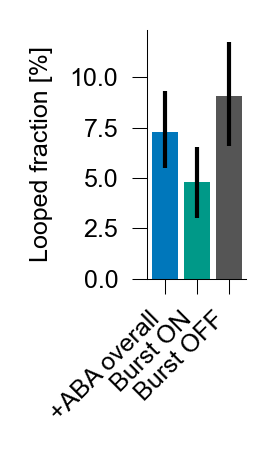

In [11]:
fig, ax = plt.subplots(figsize=(0.9,1.5), dpi=300, frameon=False)
colors_dict_states = {'+ABA overall':'#0077bb',
                      'Burst ON':'#009988',
                      'Burst OFF':'#555555'}
x = 0
for state in ['+ABA overall', 'Burst ON', 'Burst OFF']:
    y = np.mean(corrected_looped_frac_bootstrap_dists[state])
    # print(x)
    y_CI_lower = np.quantile(corrected_looped_frac_bootstrap_dists[state], 0.025)
    y_CI_upper = np.quantile(corrected_looped_frac_bootstrap_dists[state], 0.975)
    ax.bar(x=[x], height=[y], color=colors_dict_states[state], yerr=[[y-y_CI_lower], [y_CI_upper-y]])
    x+=1
    print(f'Condition: {state}, mean: {y}, CI_lower: {y_CI_lower}, CI_upper: {y_CI_upper}')

ax.set_xticks([0,1,2], ['+ABA overall', 'Burst ON', 'Burst OFF'],rotation=45,ha='right')
ax.set_ylabel('Looped fraction [%]')
ax.set_yticks([0,2.5,5,7.5,10])

# ax.set_ylim(0, 11);
ax.spines[['top', 'right']].set_visible(False);

plt.tight_layout();
plt.savefig('Figures/looped_fraction_HMM_burst_called.svg',transparent=True,bbox_inches='tight')

In [11]:
data = df_comparison[df_comparison['Condition']=='txn']
track_ids = data['TrackID'].unique()
n_tracks = len(track_ids)
frac_stats = {}
for comparison in itertools.combinations(['+ABA overall', 'Burst ON', 'Burst OFF'],2):
    name = f'{comparison[0]} vs {comparison[1]}'
    # stat = stats.mannwhitneyu(corrected_looped_frac_bootstrap_dists[comparison[0]],
    #                           corrected_looped_frac_bootstrap_dists[comparison[1]]).pvalue
    stat = (np.mean(corrected_looped_frac_bootstrap_dists[comparison[0]])-
            np.mean(corrected_looped_frac_bootstrap_dists[comparison[1]]))/np.sqrt(
                np.std(corrected_looped_frac_bootstrap_dists[comparison[0]],ddof=1)**2+
                np.std(corrected_looped_frac_bootstrap_dists[comparison[1]],ddof=1)**2
            )
    pval = scipy.stats.t.sf(np.abs(stat),n_tracks*2-2)*2*3
    frac_stats[name] = pval
frac_stats

{'+ABA overall vs Burst ON': 0.20307832372197443,
 '+ABA overall vs Burst OFF': 0.8857644339028958,
 'Burst ON vs Burst OFF': 0.027252326088763133}

In [66]:
with open("loop_fractions_bootstrap_dists_HMM_burst_called.pkl",'wb') as f:
    pickle.dump(corrected_looped_frac_bootstrap_dists,f)

In [8]:
df_comparison.to_csv('20260917_Fbn2.2_all_tracks.csv',index=False)

Figure saved to: Figures/3D_distance_distributions_final.svg


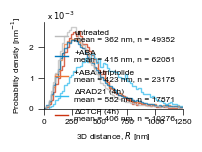

In [15]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import rcParams
import matplotlib.ticker as ticker


rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['pdf.fonttype'] = 42 
rcParams['ps.fonttype'] = 42

condition_name_map = {
    'unt': 'untreated',
    'txn': '+ABA',
    'trp': '+ABA +triptolide',
    'dRad21': '\u0394RAD21 (4h)',
    'dCtcf': '\u0394CTCF (4h)'
    }

# conditions_to_plot = {
#     'G7B8G2_GSK': '#0077BB',
#     'S+V-A6B8_GSK': '#EE7733',
#     'G7B8G2_GSK_500nMdTAG13added2hrBefore': '#CC3311',
#     'G7B8G2_GSK_100uM_IAAadded2hrBefore': '#33BBEE',
#     '14A-A11E6_GSK': '#BBBBBB'
# }
conditions_to_plot = {
    'unt': '#BBBBBB',
    'txn': '#0077BB',
    'trp': '#ee7733',
    'dRad21': '#33bbee',
    'dCtcf': '#cc3311'
    }
# track_counts = {
#     'unt': 256,
#     'txn': 256,
#     'trp': 239,
#     'dRad21': 34
# }
if 'df_comparison' in locals():
    df_plot = df_comparison[
        (df_comparison['QC_Status'] == 'After QC') & 
        (df_comparison['Condition'].isin(conditions_to_plot.keys()))
    ].copy()

    if not df_plot.empty:
        df_plot['locus_distance_nm'] = df_plot['locus_distance_um'] * 1000.0

        fig, ax = plt.subplots(figsize=(2,1.5)) 
        
        ax.grid(False)

        bins = np.linspace(0, 1500, 75) 
        lines = []
        labels = []

        for cond, color in conditions_to_plot.items().__reversed__():
            data = df_plot[df_plot['Condition'] == cond]['locus_distance_nm'].dropna()
            if len(data) == 0:
                continue
                
            mean_val = data.mean()
            label_name = condition_name_map.get(cond, cond)
            
            counts, bin_edges = np.histogram(data, bins=bins, density=True)
            
            counts_scaled = counts * 1e3 
            
            ax.stairs(counts_scaled, bin_edges, color=color, linewidth=1.0,alpha=0.75)
            
            lines.append(plt.Line2D([0], [0], color=color, linewidth=1.0))
            labels.append(f"{label_name}\nmean = {mean_val:.0f} nm, n = {len(data)}")

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        
        ax.spines['left'].set_visible(True)
        ax.spines['left'].set_color('black')
        ax.spines['left'].set_linewidth(0.5)
        
        ax.spines['bottom'].set_visible(True)
        ax.spines['bottom'].set_color('black')
        ax.spines['bottom'].set_linewidth(0.5)

        ax.set_xlim(0, 1250)
        ax.set_xticks([0, 250, 500, 750, 1000, 1250])
        
        ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=5))

        ax.text(0.02, 1.0, r"x $10^{-3}$", transform=ax.transAxes, fontsize=6, color='black', va='bottom', ha='left')

        ax.set_xlabel(r"3D distance, $\mathit{R}$ [nm]", fontsize=6, color='black')
        ax.set_ylabel(r"Probability density [nm$^{-1}$]", fontsize=6, color='black')
        
        # ax.set_title("3D distance distributions (PDF)", fontsize=7, color='black', pad=15)

        ax.tick_params(axis='both', which='major', labelsize=6, labelcolor='black', 
                       color='black', direction='out', width=0.5, length=4, 
                       bottom=True, left=True)

        leg = ax.legend(lines[::-1], labels[::-1], frameon=False, fontsize=6, loc='upper right', 
                        handlelength=1.5, labelspacing=0.8)

        plt.tight_layout()
        
        os.makedirs('Figures', exist_ok=True)
        
        save_path = os.path.join('Figures', '3D_distance_distributions_final.svg')
        plt.savefig(save_path, format='svg', dpi=1000, bbox_inches='tight', transparent=True)
        print(f"Figure saved to: {save_path}")

        plt.show()
    else:
        print("Data source is empty for the specified conditions.")
else:
    print("DataFrame 'df_comparison' not found.")

In [12]:
np.unique(df_comparison['Condition'])

array(['dCtcf', 'dRad21', 'trp', 'txn', 'unt'], dtype=object)

In [13]:
conds = ['txn','trp','dRad21','dCtcf']
dist_stats = {}
for c in conds:
	name = f'Unt vs {c}'
	pval = stats.ks_2samp(df_plot['locus_distance_nm'][df_plot['Condition']=='unt'],
	                      df_plot['locus_distance_nm'][df_plot['Condition']==c],
                          nan_policy='omit').pvalue*4
	dist_stats[name]=pval
dist_stats

{'Unt vs txn': 2.4431682690541383e-199,
 'Unt vs trp': 2.692079724667257e-112,
 'Unt vs dRad21': 0.0,
 'Unt vs dCtcf': 4.3089363967398472e-78}

In [ ]:
# get trajectory ids 

In [ ]:
emission, lengths = extract_intensity_series(filtered_df,'txn')
model = hmm.GaussianHMM(n_components=2).fit(emission,lengths)
model

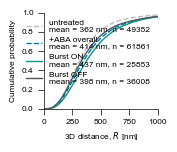

In [18]:
df_active = df_comparison.loc[(df_comparison['Condition']=='txn') & (df_comparison['Burst']=='on')]
df_inactive = df_comparison.loc[(df_comparison['Condition']=='txn') & (df_comparison['Burst']=='off')]
dfs = [df_active, df_inactive]
colors = ['#009988','#555555']
label_names = [f'Burst ON',f'Burst OFF']
fig, ax = plt.subplots(figsize=(1.75, 1.5)) 
        
ax.grid(False)

bins = np.linspace(0, 1500, 76) 
lines = []
labels = []
unt_data = df_comparison.loc[df_comparison['Condition']=='unt']
unt_data = unt_data['locus_distance_um'].dropna()*1000
ax.ecdf(unt_data,color='#bbbbbb',linewidth=1,ls='--')
lines.append(plt.Line2D([0],[0],color='#bbbbbb',linewidth=1,ls='--'))
labels.append(f"untreated \nmean = {unt_data.mean():.0f} nm, n = {len(unt_data)}")
txn_data = pd.concat([df_active,df_inactive])
txn_data = txn_data['locus_distance_um'].dropna()*1000
ax.ecdf(txn_data,color='#0077bb',linewidth=1,ls='--')
lines.append(plt.Line2D([0],[0],color='#0077bb',linewidth=1,ls='--'))
labels.append(f"+ABA overall \nmean = {txn_data.mean():.0f} nm, n = {len(txn_data)}")
for i in range(len(dfs)):
    data = dfs[i]['locus_distance_um'].dropna()*1000
    if len(data) == 0:
        continue
        
    mean_val = data.mean()
    median_val = data.median()
    label_name = label_names[i]
    
    # counts, bin_edges = np.histogram(data, bins=bins, density=True)
    
    # counts_scaled = counts * 1e3 
    
    # ax.stairs(counts_scaled, bin_edges, color=colors[i], linewidth=1.0)
    ax.ecdf(data,color=colors[i],linewidth=1)
    
    lines.append(plt.Line2D([0], [0], color = colors[i], linewidth=1))
    labels.append(f"{label_name}\nmean = {mean_val:.0f} nm, n = {len(data)}")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_visible(True)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(0.5)

ax.spines['bottom'].set_visible(True)
ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(0.5)

ax.set_xlim(0, 1000)
ax.set_xticks([0, 250, 500, 750, 1000])

ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=False, nbins=5))

# ax.text(0.02, 1.0, r"x $10^{-3}$", transform=ax.transAxes, fontsize=6, color='black', va='bottom', ha='left')

ax.set_xlabel(r"3D distance, $\mathit{R}$ [nm]", fontsize=6, color='black')
# ax.set_ylabel(r"Probability density [nm$^{-1}$]", fontsize=6, color='black')
ax.set_ylabel("Cumulative probability", fontsize=6, color='black')

# ax.set_title("3D distance distributions (CDF)", fontsize=7, color='black', pad=15)

ax.tick_params(axis='both', which='major', labelsize=6, labelcolor='black', 
                color='black', direction='out', width=0.5, length=4, 
                bottom=True, left=True)

leg = ax.legend(lines, labels, frameon=False, fontsize=6, loc='best')

plt.tight_layout()
plt.savefig('Figures/distance_CDF_txn_HMM_burst_detected.svg',
            transparent=True,bbox_inches='tight')
plt.show()

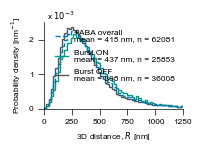

In [25]:
dfs = [df_inactive,df_active,df_comparison[df_comparison["Condition"]=='txn']]
colors = ['#555555',"#009988",'#0077bb']
names = ['Burst OFF','Burst ON','+ABA overall']
linestyles = ['-','-','--']
fig, ax = plt.subplots(figsize=(2,1.5)) 

ax.grid(False)

bins = np.linspace(0, 1500, 75) 
lines = []
labels = []
for i in range(len(dfs)):
	data = dfs[i]['locus_distance_um'].dropna()*1000
	if len(data) == 0:
		continue
		
	mean_val = data.mean()
	label_name = names[i]
	
	counts, bin_edges = np.histogram(data, bins=bins, density=True)
	
	counts_scaled = counts * 1e3 
	
	ax.stairs(counts_scaled, bin_edges, color=colors[i], linewidth=1.0,alpha=1,
	          ls=linestyles[i])
	
	lines.append(plt.Line2D([0], [0], color=colors[i], linewidth=1.0,
	                        ls=linestyles[i]))
	labels.append(f"{label_name}\nmean = {mean_val:.0f} nm, n = {len(data)}")
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_visible(True)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(0.5)

ax.spines['bottom'].set_visible(True)
ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(0.5)

ax.set_xlim(0, 1250)
ax.set_xticks([0, 250, 500, 750, 1000, 1250])

ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=5))

ax.text(0.02, 1.0, r"x $10^{-3}$", transform=ax.transAxes, fontsize=6, color='black', va='bottom', ha='left')

ax.set_xlabel(r"3D distance, $\mathit{R}$ [nm]", fontsize=6, color='black')
ax.set_ylabel(r"Probability density [nm$^{-1}$]", fontsize=6, color='black')

# ax.set_title("3D distance distributions (PDF)", fontsize=7, color='black', pad=15)

ax.tick_params(axis='both', which='major', labelsize=6, labelcolor='black', 
				color='black', direction='out', width=0.5, length=4, 
				bottom=True, left=True)

leg = ax.legend(lines[::-1], labels[::-1], frameon=False, fontsize=6, loc='upper right', 
				handlelength=1.5, labelspacing=0.8)

plt.tight_layout()
plt.savefig('/mnt/md0/Jamie/analysis/Figures/dist_distributions_by_burst.svg',
			transparent=True,bbox_inches='tight')
plt.show()

In [ ]:
# load data from Gabriele et al 2022
C36_data = nl.io.load.hdf5("2022_Fbn2_full_data.h5")['data']
C36_data.makeSelection('C36')
C36_dists = []
for traj in C36_data:
	traj_data = traj[:]*1000
	traj_dists = np.linalg.norm(traj_data,axis=1)
	C36_dists.append(traj_dists)
C36_dists = np.concatenate(C36_dists)
C36_dists = C36_dists[~np.isnan(C36_dists)]
print(C36_dists.shape)

(46163,)


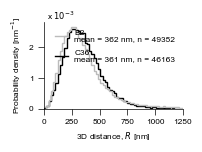

In [15]:
unt_dists = df_comparison[df_comparison['Condition']=='unt']['locus_distance_um'].dropna()*1000
dist_sets = [C36_dists,unt_dists]
colors = ['#000000',"#bbbbbb"]
names = ['C36','B2']
fig, ax = plt.subplots(figsize=(2,1.5)) 

ax.grid(False)

bins = np.linspace(0, 1500, 75) 
lines = []
labels = []
for i in range(len(dist_sets)):
	data = dist_sets[i]
	if len(data) == 0:
		continue
		
	mean_val = np.mean(data)
	label_name = names[i]
	
	counts, bin_edges = np.histogram(data, bins=bins, density=True)
	
	counts_scaled = counts * 1e3 
	
	ax.stairs(counts_scaled, bin_edges, color=colors[i], linewidth=1.0,alpha=1)
	
	lines.append(plt.Line2D([0], [0], color=colors[i], linewidth=1.0))
	labels.append(f"{label_name}\nmean = {mean_val:.0f} nm, n = {len(data)}")
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_visible(True)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(0.5)

ax.spines['bottom'].set_visible(True)
ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(0.5)

ax.set_xlim(0, 1250)
ax.set_xticks([0, 250, 500, 750, 1000, 1250])

ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=5))

ax.text(0.02, 1.0, r"x $10^{-3}$", transform=ax.transAxes, fontsize=6, color='black', va='bottom', ha='left')

ax.set_xlabel(r"3D distance, $\mathit{R}$ [nm]", fontsize=6, color='black')
ax.set_ylabel(r"Probability density [nm$^{-1}$]", fontsize=6, color='black')

# ax.set_title("3D distance distributions (PDF)", fontsize=7, color='black', pad=15)

ax.tick_params(axis='both', which='major', labelsize=6, labelcolor='black', 
				color='black', direction='out', width=0.5, length=4, 
				bottom=True, left=True)

leg = ax.legend(lines[::-1], labels[::-1], frameon=False, fontsize=6, loc='upper right', 
				handlelength=1.5, labelspacing=0.8)

plt.tight_layout()
plt.savefig('/mnt/md0/Jamie/analysis/Figures/unt_vs_c36_dists.svg',
			transparent=True,bbox_inches='tight')
plt.show()

In [16]:
c36_stats = scipy.stats.ks_2samp(unt_dists,C36_dists,nan_policy='omit')
c36_stats

KstestResult(statistic=0.058460192455464466, pvalue=2.67043541472467e-71, statistic_location=294.77420269927825, statistic_sign=1)

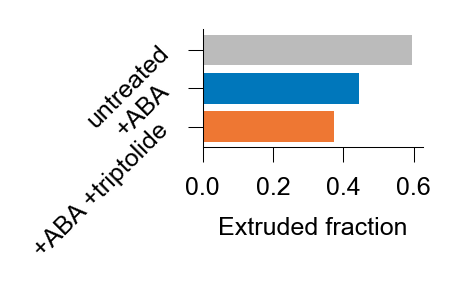

In [83]:
msd_asymptotes = {'unt':356.67,
                  'txn':490.4,
                  'trp':552.83,
                  'dRad21':882.11}
y=2
fig,ax = plt.subplots(figsize=(1.5,0.9),dpi=300,frameon=False)
for cond in ['unt','txn','trp']:
    ax.barh(width=(msd_asymptotes['dRad21']-msd_asymptotes[cond])/msd_asymptotes['dRad21'],y=[y],color=colors_dict[cond])
    y-=1
ax.set_yticks([2,1,0], [condition_name_map[condition] for condition in ['unt','txn','trp']],rotation=45,ha='right')
ax.set_xlabel('Extruded fraction')
ax.set_xticks([0,0.2,0.4,0.6])
ax.spines[['top', 'right']].set_visible(False);
fig.align_ylabels()
plt.tight_layout()
plt.show()

In [ ]:
df_active['locus_distance_um'].to_numpy()

In [21]:
active_dists = df_active['locus_distance_um'].to_numpy()
inactive_dists = df_inactive['locus_distance_um'].to_numpy()
stats = scipy.stats.ks_2samp(active_dists,inactive_dists,nan_policy='omit').pvalue*2
stats

6.911188462867486e-107

In [23]:
unt_dists = df_comparison['locus_distance_um'].loc[df_comparison['Condition']=='unt'].to_numpy()
stats2 = scipy.stats.ks_2samp(inactive_dists,unt_dists,nan_policy='omit').pvalue*2
stats2

4.848328021200179e-60

In [ ]:
fig, ax = plt.subplots(figsize=(3.5, 2.5)) 

In [ ]:
import pickle
with open('/mnt/md1/Jamie/msd_fits/fit_results/fit_params_unt.pkl','rb') as f:
    test_params = pickle.load(f)

test_params

In [ ]:
fig,ax = plt.subplots(1,1,figsize=(3.5,2.5))
sns.scatterplot(df_comparison.loc[df_comparison['Condition']=='txn'],x='locus_distance_um',y='intensity (au)',ax=ax,alpha=0.5,size=0.05,color='#0077bb')
sns.kdeplot(df_comparison.loc[df_comparison['Condition']=='txn'],x='locus_distance_um',y='intensity (au)',ax=ax,color='#000000')
ax.grid(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_visible(True)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(0.5)

ax.spines['bottom'].set_visible(True)
ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(0.5)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=False, nbins=7))

ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=6))
ax.tick_params(axis='both', which='major', labelsize=6, labelcolor='black', 
                color='black', direction='out', width=0.5, length=4, 
                bottom=True, left=True)
ax.get_legend().remove()
ax.set_xlabel('Locus distance [um]')
ax.set_ylabel('MS2 intensity [AU]')
ax.set_title('MS2 vs locus distance, +ABA')
# plt.savefig('Figures/ms2_vs_dist_txn.svg',transparent=True,bbox_inches='tight')
plt.show()

In [ ]:
fig,ax = plt.subplots(1,1,figsize=(3.5,2.5))
sns.scatterplot(df_comparison.loc[df_comparison['Condition']=='trp'],x='locus_distance_um',y='intensity (au)',ax=ax,alpha=0.5,size=0.05,color='#009988')
sns.kdeplot(df_comparison.loc[df_comparison['Condition']=='trp'],x='locus_distance_um',y='intensity (au)',ax=ax,color='#000000')
ax.grid(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_visible(True)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(0.5)

ax.spines['bottom'].set_visible(True)
ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(0.5)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=False, nbins=7))

ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=6))
ax.tick_params(axis='both', which='major', labelsize=6, labelcolor='black', 
                color='black', direction='out', width=0.5, length=4, 
                bottom=True, left=True)
ax.get_legend().remove()
ax.set_xlabel('Locus distance [um]')
ax.set_ylabel('MS2 intensity [AU]')
ax.set_title('MS2 vs locus distance, +ABA')
# plt.savefig('Figures/ms2_vs_dist_trp.svg',transparent=True,bbox_inches='tight')
plt.show()

In [ ]:
fig,ax = plt.subplots(1,1,figsize=(3.5,2.5))
sns.scatterplot(df_comparison.loc[df_comparison['Condition']=='unt'],x='locus_distance_um',y='intensity (au)',ax=ax,alpha=0.5,size=0.05,color='#bbbbbb')
sns.kdeplot(df_comparison.loc[df_comparison['Condition']=='unt'],x='locus_distance_um',y='intensity (au)',ax=ax,color='#000000')
ax.grid(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_visible(True)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(0.5)

ax.spines['bottom'].set_visible(True)
ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(0.5)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=False, nbins=7))

ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=6))
ax.tick_params(axis='both', which='major', labelsize=6, labelcolor='black', 
                color='black', direction='out', width=0.5, length=4, 
                bottom=True, left=True)
ax.get_legend().remove()
ax.set_xlabel('Locus distance [um]')
ax.set_ylabel('MS2 intensity [AU]')
ax.set_title('MS2 vs locus distance, untreated')
# plt.savefig('Figures/ms2_vs_dist_unt.svg',transparent=True,bbox_inches='tight')
plt.show()

In [ ]:
fig,ax = plt.subplots(1,1,figsize=(3,2))
# sns.kdeplot(df_comparison.loc[df_comparison['Condition']=='unt'],x='locus_distance_um',y='intensity (au)',ax=ax,color='#bbbbbb')
# sns.kdeplot(df_comparison.loc[df_comparison['Condition']=='txn'],x='locus_distance_um',y='intensity (au)',ax=ax,color='#0077bb')
sns.kdeplot(df_comparison,x='locus_distance_um',y='intensity (au)', hue='Condition', alpha=0.5, palette=conditions_to_plot,
            hue_order = ['unt','txn', 'trp'])
ax.grid(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_visible(True)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(0.5)

ax.spines['bottom'].set_visible(True)
ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(0.5)
# ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=False, nbins=7))
# ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=6))
ax.set_xlim(-0.1,2)
ax.set_ylim(-6,12)
ax.tick_params(axis='both', which='major', labelsize=6, labelcolor='black', 
                color='black', direction='out', width=0.5, length=4, 
                bottom=True, left=True)
ax.set_xlabel('Locus distance [um]')
ax.set_ylabel('MS2 intensity [AU]')
ax.set_title('MS2 vs locus distance')
# plt.savefig('Figures/ms2_vs_dist_comparison.svg',transparent=True,bbox_inches='tight')
plt.show()